# How long will a condition sign-off take, and what drives it?

This notebook follows on from `02_late_model.ipynb` and does three things:

1. **Predict days to decision**, not just late or on time.
2. **Compare feature importance across all five models** (two late/on-time models and three days models) to find the predictors they agree on.
3. **Show how to add external data**, with a worked example using house prices already in this folder, and a ranked list of sources from the team's Data Asset Register.

Same applications, features and time split as `02_late_model.ipynb`. That code now lives in `src/conditions_queue/features.py`, so both notebooks build exactly the same table.

## 1 · Load the data

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))  # run from notebooks/: make src/ importable
from conditions_queue import paths

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import mean_absolute_error, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.duration.hazard_regression import PHReg

from conditions_queue.features import CAT, NUM, TOPIC_COLS, LABELS, load_dataset, time_split, concordance

pd.set_option("display.width", 160)
d = load_dataset()
train, test = time_split(d)
print(f"{len(d):,} applications · train {len(train):,} (2021-23) · test {len(test):,} (2024-25)")
print(f"Still undecided when fetched: {(d['decided'] == 0).sum():,}")

16,284 applications · train 10,705 (2021-23) · test 5,579 (2024-25)
Still undecided when fetched: 854


### The target variable

| | Late / on time (`02_late_model.ipynb`) | Decision time (this notebook) |
|---|---|---|
| **Target** | `late` = 1 if the decision took more than 56 days | `days` = days from `start_date` (submission) to `decided_date` (decision) |
| **Undecided applications** | Counted as late, because they're already past 56 days | `days` = days from submission to when the data was fetched, flagged `decided = 0` (still running) |
| **How models use it** | Classifiers predict the chance of being late | Ridge and LightGBM predict **log(1 + days)** for decided applications. The Cox survival model uses `days` with `decided` as the event flag. The P50/P90 models predict days directly |
| **Main score** | AUC | C-index (ordering), plus average and median error in days |

## 2 · Why days is harder than late / on time

- **The tail is long.** Most decisions arrive around 8 weeks, but some take years. One very slow case can swamp an average, so we model the **log** of days, which squashes the tail.
- **854 applications have no decision yet.** We know they've taken *at least* this long, but not the final number. This is called **censoring**. Dropping them would bias every estimate downwards. A **survival model** (Cox) is built for exactly this: it uses the "at least" information properly.

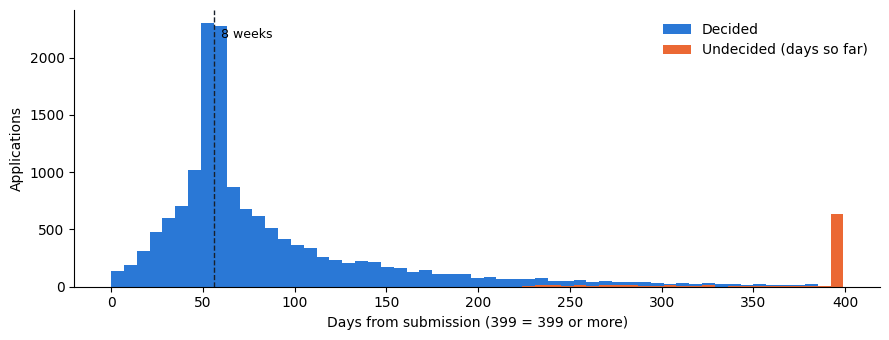

,count,mean,std,min,25%,50%,75%,max
decided,,,,,,,,
0,854.0,720.0,460.0,220.0,385.0,538.0,922.0,2042.0
1,15430.0,98.0,105.0,0.0,50.0,60.0,106.0,1272.0


In [2]:
fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.arange(0, 400, 7)
ax.hist(d.loc[d["decided"] == 1, "days"].clip(upper=399), bins=bins, color="#2a78d6", label="Decided")
ax.hist(d.loc[d["decided"] == 0, "days"].clip(upper=399), bins=bins, color="#eb6834", label="Undecided (days so far)")
ax.axvline(56, color="#18202b", ls="--", lw=1); ax.text(60, ax.get_ylim()[1] * 0.9, "8 weeks", fontsize=9)
ax.set_xlabel("Days from submission (399 = 399 or more)"); ax.set_ylabel("Applications")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
d.groupby("decided")["days"].describe().round(0)

## 3 · Five models

| Model | Target | Uses undecided apps? | Why include it |
|---|---|---|---|
| Logistic regression | late (yes/no) | as late | From `02_late_model.ipynb`, for comparison |
| LightGBM classifier | late (yes/no) | as late | From `02_late_model.ipynb`, for comparison |
| Ridge regression | log(days) | no | Simple linear model of days |
| LightGBM regressor | log(days) | no | Non-linear model of days |
| **Cox survival model** | days + decided yet? | **yes, as censored** | Handles undecided apps properly; gives readable "speed" ratios |

**One score for all five: the C-index (concordance).** Take two applications. If the model says A will take longer than B, does it really? C-index is the share of pairs it orders correctly. 0.5 is a coin flip and 1.0 is perfect. It works for undecided apps too: if A is still undecided after 300 days and B was decided in 40, we know A took longer.

In [3]:
FEATS = CAT + NUM
medians = train[NUM].median()
cat_levels = {c: train[c].astype("category").cat.categories for c in CAT}

def prep_linear(X):
    return X[FEATS].fillna(medians)

def prep_tree(X):
    X = X[FEATS].copy()
    for c in CAT:
        X[c] = pd.Categorical(X[c], categories=cat_levels[c])
    return X

def encoder():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT), ("num", StandardScaler(), NUM)])

GBM = dict(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=40,
           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=0, verbose=-1)

train_dec, test_dec = train[train["decided"] == 1], test[test["decided"] == 1]
log_days = np.log1p(train_dec["days"])

# each entry: (kind, predict function). For 'days' models, bigger output = predicted to take longer.
models = {}

logit = make_pipeline(encoder(), LogisticRegression(max_iter=2000, C=0.5)).fit(prep_linear(train), train["late"])
models["Late · logistic"] = ("late", lambda X: logit.predict_proba(prep_linear(X))[:, 1])

gbm_late = lgb.LGBMClassifier(**GBM).fit(prep_tree(train), train["late"])
models["Late · LightGBM"] = ("late", lambda X: gbm_late.predict_proba(prep_tree(X))[:, 1])

ridge = make_pipeline(encoder(), Ridge(alpha=1.0)).fit(prep_linear(train_dec), log_days)
models["Days · ridge"] = ("days", lambda X: np.expm1(ridge.predict(prep_linear(X))))

gbm_days = lgb.LGBMRegressor(**GBM).fit(prep_tree(train_dec), log_days)
models["Days · LightGBM"] = ("days", lambda X: np.expm1(gbm_days.predict(prep_tree(X))))

In [4]:
# Cox proportional hazards (statsmodels). "Hazard" here = the chance of getting a decision on a given day.
cox_enc = encoder().fit(prep_linear(train))
names = cox_enc.get_feature_names_out()

# drop one reference level per category (the most common) and very rare levels, so the model is solvable
keep = np.ones(len(names), bool)
for c in CAT:
    counts = train[c].value_counts()
    for i, n in enumerate(names):
        if n.startswith(f"cat__{c}_"):
            level = n[len(f"cat__{c}_"):]
            if level == counts.index[0] or counts.get(level, 0) < 30:
                keep[i] = False

def cox_matrix(X):
    Z = cox_enc.transform(prep_linear(X))
    return (Z.toarray() if hasattr(Z, "toarray") else Z)[:, keep]

cox = PHReg(train["days"].clip(lower=0.5).values, cox_matrix(train), status=train["decided"].values, ties="efron").fit()
# higher hazard = decided sooner, so flip the sign to get "takes longer" scores
models["Days · Cox (survival)"] = ("days", lambda X: -(cox_matrix(X) @ cox.params))
print("Fitted:", ", ".join(models))

Fitted: Late · logistic, Late · LightGBM, Days · ridge, Days · LightGBM, Days · Cox (survival)


## 4 · How good are they?

Two baselines to beat:
- **Borough median:** predict each borough's median days from the training years.
- For the late/on-time models, AUC is shown as well, as in `02_late_model.ipynb`.

**MAE** (mean absolute error) is the average number of days the prediction is off by, for decided applications.

In [5]:
borough_median = train_dec.groupby("area_name")["days"].median()
fallback = train_dec["days"].median()

rows = [{"model": "Borough median (baseline)",
         "C-index": concordance(test["days"], test["decided"], test["area_name"].map(borough_median).fillna(fallback)),
         "MAE (days)": mean_absolute_error(test_dec["days"], test_dec["area_name"].map(borough_median).fillna(fallback)),
         "AUC (late)": np.nan}]
for name, (kind, f) in models.items():
    p = f(test)
    rows.append({"model": name,
                 "C-index": concordance(test["days"], test["decided"], p),
                 "MAE (days)": mean_absolute_error(test_dec["days"], f(test_dec)) if name in ("Days · ridge", "Days · LightGBM") else np.nan,
                 "AUC (late)": roc_auc_score(test["late"], p) if kind == "late" else np.nan})
scores = pd.DataFrame(rows).set_index("model")
scores.round(3)

,C-index,MAE (days),AUC (late)
model,,,
Borough median (baseline),0.547,36.560,NaN
Late · logistic,0.575,NaN,0.615
Late · LightGBM,0.583,NaN,0.628
Days · ridge,0.561,39.624,NaN
Days · LightGBM,0.558,41.388,NaN
Days · Cox (survival),0.570,NaN,NaN


**Reading this:**
- Every model ranks applications better than the borough median (C-index about 0.56–0.58 against 0.55), but not by much.
- On **average error in days**, the models don't beat the borough median. Predicting an exact number of days is close to impossible with this data. The borough median is already about as good as it gets, at roughly 5 weeks off on average.
- The **late/on-time models rank days best**. The 8-week deadline is the strongest structure in the data, and those models are trained on exactly that.

So the honest answer to "how many days?" is a **range**, not a number.

### A range instead of a number: P50 and P90

LightGBM can predict quantiles directly. **P50** is the typical time, and **P90** is the "very probably decided by" time. If the P90 is right, about 90% of applications should be decided before it.

In [6]:
q50 = lgb.LGBMRegressor(objective="quantile", alpha=0.5, **GBM).fit(prep_tree(train_dec), train_dec["days"])
q90 = lgb.LGBMRegressor(objective="quantile", alpha=0.9, **GBM).fit(prep_tree(train_dec), train_dec["days"])
rng_df = test_dec[["name", "area_name", "n_cond", "days"]].copy()
rng_df["P50"], rng_df["P90"] = q50.predict(prep_tree(test_dec)), q90.predict(prep_tree(test_dec))

print(f"Decided by the predicted P90: {(rng_df['days'] <= rng_df['P90']).mean():.0%}  (target 90%)")
print(f"Median error of P50: {np.median(np.abs(rng_df['days'] - rng_df['P50'])):.0f} days")
print("\nTypical predicted range by number of conditions bundled:")
rng_df.groupby(rng_df["n_cond"].clip(upper=7)).agg(applications=("days", "size"), P50=("P50", "median"),
                                                  P90=("P90", "median"), actual_median=("days", "median")).round(0)

Decided by the predicted P90: 93%  (target 90%)
Median error of P50: 24 days

Typical predicted range by number of conditions bundled:


,applications,P50,P90,actual_median
n_cond,,,,
1,4059,67.0,185.0,56.0
2,438,73.0,200.0,58.0
3,182,80.0,212.0,60.0
4,109,87.0,230.0,62.0
5,57,95.0,239.0,65.0
6,39,104.0,253.0,80.0
7,42,113.0,274.0,75.0


The P90 is a usable "plan for this" date, and it widens noticeably as more conditions are bundled. The P50 runs about 10 days high: the model learned from 2021–23, and decisions in 2024–25 were faster. Retraining on recent data would bring it down. For a developer, *"typically about 2 months, plan for up to 6"* is more honest and more useful than a single number.

### How good are the day predictions, in plain terms?

For decided test applications (2024–25): how far off is each prediction, and how often is it within two or four weeks? **Rank correlation** checks whether applications predicted to take longer really do (1 = perfect order, 0 = no relation).

In [7]:
from scipy.stats import spearmanr
actual = test_dec["days"].values
day_preds = {
    "Borough median (baseline)": test_dec["area_name"].map(borough_median).fillna(fallback).values,
    "Days · ridge": models["Days · ridge"][1](test_dec),
    "Days · LightGBM": models["Days · LightGBM"][1](test_dec),
    "Days · LightGBM P50": q50.predict(prep_tree(test_dec)),
}
acc_rows = []
for name, p in day_preds.items():
    err = np.abs(actual - p)
    acc_rows.append({"model": name, "average error (days)": err.mean(), "median error (days)": np.median(err),
                     "within 14 days": (err <= 14).mean(), "within 28 days": (err <= 28).mean(),
                     "rank correlation": spearmanr(actual, p).correlation})
days_accuracy = pd.DataFrame(acc_rows).set_index("model")
days_accuracy.style.format({"average error (days)": "{:.0f}", "median error (days)": "{:.0f}", "within 14 days": "{:.0%}",
                            "within 28 days": "{:.0%}", "rank correlation": "{:.2f}"})

,average error (days),median error (days),within 14 days,within 28 days,rank correlation
model,,,,,
Borough median (baseline),37,20,39%,62%,0.16
Days · ridge,40,26,28%,53%,0.18
Days · LightGBM,41,28,26%,49%,0.19
Days · LightGBM P50,38,24,32%,57%,0.18


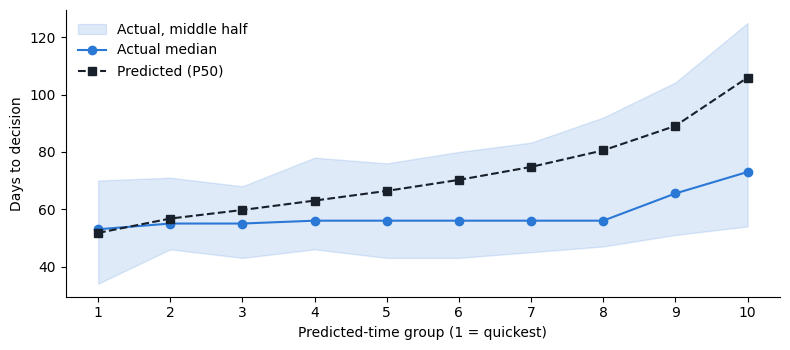

,applications,predicted_median,actual_median,actual_p25,actual_p75
group,,,,,
1,493,52.0,53.0,34.0,70.0
2,493,57.0,55.0,46.0,71.0
3,492,60.0,55.0,43.0,68.0
4,493,63.0,56.0,46.0,78.0
5,492,66.0,56.0,43.0,76.0
6,493,70.0,56.0,43.0,80.0
7,492,75.0,56.0,45.0,83.0
8,493,81.0,56.0,47.0,92.0
9,492,89.0,66.0,51.0,104.0


In [8]:
# Predicted vs actual: split test applications into ten groups by the P50 prediction
cal = pd.DataFrame({"pred": day_preds["Days · LightGBM P50"], "actual": actual})
cal["group"] = pd.qcut(cal["pred"].rank(method="first"), 10, labels=range(1, 11))
days_calibration = cal.groupby("group", observed=True).agg(
    applications=("actual", "size"), predicted_median=("pred", "median"), actual_median=("actual", "median"),
    actual_p25=("actual", lambda s: s.quantile(0.25)), actual_p75=("actual", lambda s: s.quantile(0.75)))

fig, ax = plt.subplots(figsize=(8, 3.6))
xg = np.arange(1, 11)
ax.fill_between(xg, days_calibration["actual_p25"], days_calibration["actual_p75"], color="#2a78d6", alpha=0.15, label="Actual, middle half")
ax.plot(xg, days_calibration["actual_median"], "o-", color="#2a78d6", label="Actual median")
ax.plot(xg, days_calibration["predicted_median"], "s--", color="#18202b", label="Predicted (P50)")
ax.set_xticks(xg); ax.set_xlabel("Predicted-time group (1 = quickest)"); ax.set_ylabel("Days to decision")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()
days_calibration.round(0)

**Reading this:**
- **Most decisions arrive around day 56 whatever the application.** In the middle six predicted-time groups, the actual median is 55–56 days every time. Councils work to the deadline, so there's little variation left to predict for most applications.
- **That makes the borough median hard to beat on error.** It's off by a median of 20 days and lands within 4 weeks 62% of the time. The models are further off on average (median error 24–28 days), mainly because they learned from 2021–23, when decisions were slower, and so they predict too high.
- **The models are better at ordering.** Their rank correlation (0.18–0.19) beats the borough median's (0.16), and the slowest predicted groups really are the slowest: the actual median rises to 66 and 73 days, and the middle half stretches to 104 and 125 days.
- **So use the days models to flag the slow tail, not to promise a date.** The P90 "plan for" date is the useful output: 93% of applications were decided before it.

### Reading the Cox model: what speeds decisions up or slows them down

A **speed ratio** (hazard ratio) above 1 means decisions come faster, and below 1 means slower. For example, 0.64 means the daily chance of getting a decision is 36% lower. Categories are compared with their most common level: Croydon for borough (`area_name`), Small for application size (`app_size`), Conditions for application type (`app_type`), and Unknown for scheme size band (`band`). Each label ends with its column name in brackets. Numeric features are per one standard deviation. Only effects whose 95% range doesn't cross 1 are shown.

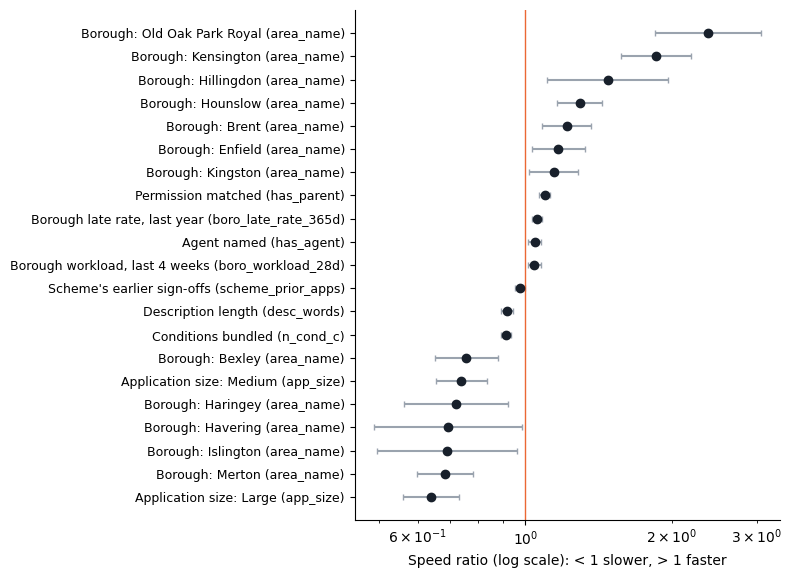

Each extra condition bundled multiplies the daily chance of a decision by 0.92 (8% slower per condition)


In [9]:
hr = pd.DataFrame({"speed ratio": np.exp(cox.params),
                   "low": np.exp(cox.conf_int()[:, 0]), "high": np.exp(cox.conf_int()[:, 1])},
                  index=names[keep])
PREFIX = {"area_name": "Borough", "app_size": "Application size", "app_type": "Application type", "band": "Scheme size band"}
def readable(n):
    n = n.replace("cat__", "").replace("num__", "")
    for col, lab in PREFIX.items():
        if n.startswith(col + "_"):
            return f"{lab}: {n[len(col) + 1:]} ({col})"
    return LABELS.get(n, n)
hr.index = [readable(n) for n in hr.index]
show =hr[(hr["low"] > 1) | (hr["high"] < 1)].sort_values("speed ratio")  # only clearly non-zero effects

fig, ax = plt.subplots(figsize=(8, max(3, 0.28 * len(show))))
y = np.arange(len(show))
ax.errorbar(show["speed ratio"], y, xerr=[show["speed ratio"] - show["low"], show["high"] - show["speed ratio"]],
            fmt="o", color="#18202b", ecolor="#9aa3ae", capsize=2)
ax.axvline(1, color="#eb6834", lw=1)
ax.set_yticks(y); ax.set_yticklabels(show.index, fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("Speed ratio (log scale): < 1 slower, > 1 faster")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

sd = train["n_cond_c"].std()
per_cond = np.exp(cox.params[list(names[keep]).index("num__n_cond_c")] / sd)
print(f"Each extra condition bundled multiplies the daily chance of a decision by {per_cond:.2f} "
      f"({(1 - per_cond):.0%} slower per condition)")

## 5 · The biggest predictors, across all five models

Each model is tested the same way: **shuffle one feature in the test set and measure how much the score drops**. Shuffling breaks the link between that feature and the outcome, so a big drop means the model relies on it. The score is AUC for the late models and C-index for the days models.

The 16 topic flags are shuffled **together** as one group, "Condition topics", so they're judged as a set rather than 16 tiny pieces.

To compare models fairly, each model's drops are turned into **shares** that add up to 100%, then averaged.

In [10]:
GROUPS = {f: [f] for f in FEATS if f not in TOPIC_COLS}
GROUPS["topics"] = TOPIC_COLS

def model_score(kind, X, p):
    return roc_auc_score(X["late"], p) if kind == "late" else concordance(X["days"], X["decided"], p)

rng = np.random.default_rng(0)
drops = {}
for name, (kind, f) in models.items():
    base = model_score(kind, test, f(test))
    drops[name] = {}
    for g, cols in GROUPS.items():
        d_list = []
        for _ in range(3):
            shuffled = test.copy()
            shuffled[cols] = shuffled[cols].values[rng.permutation(len(shuffled))]
            d_list.append(base - model_score(kind, shuffled, f(shuffled)))
        drops[name][g] = np.mean(d_list)

drops = pd.DataFrame(drops)
share = drops.clip(lower=0) / drops.clip(lower=0).sum() * 100
summary = pd.DataFrame({"average share %": share.mean(axis=1),
                        "average rank": drops.rank(ascending=False).mean(axis=1),
                        "top 5 in how many models": (drops.rank(ascending=False) <= 5).sum(axis=1)})
summary = summary.join(share.round(1)).sort_values("average share %", ascending=False)
summary.index = summary.index.map(lambda k: LABELS.get(k, k))
summary.round(1).head(12)

,average share %,average rank,top 5 in how many models,Late · logistic,Late · LightGBM,Days · ridge,Days · LightGBM,Days · Cox (survival)
Application size (app_size),28.4,1.6,5,37.2,31.3,29.2,22.5,21.9
Borough (area_name),27.0,1.6,5,17.0,31.6,17.3,33.8,35.4
Conditions bundled (n_cond_c),10.3,3.4,5,8.3,9.0,10.0,14.7,9.6
Condition topics (16 t_* flags),8.1,4.0,5,8.0,9.7,7.0,9.8,6.0
Description length (desc_words),5.4,5.6,2,5.3,6.4,5.0,5.6,4.6
Application type (app_type),4.5,10.0,1,2.6,0.5,18.4,0.9,0.1
Permission matched (has_parent),2.8,9.6,0,3.8,1.5,4.7,0.0,4.0
Homes known (homes_known),2.8,10.4,2,6.9,0.0,2.4,0.0,4.7
Agent named (has_agent),2.5,8.4,0,2.7,1.1,3.2,1.2,4.4
Number of topics (n_topics),1.7,10.0,0,0.3,2.2,0.7,5.2,0.2


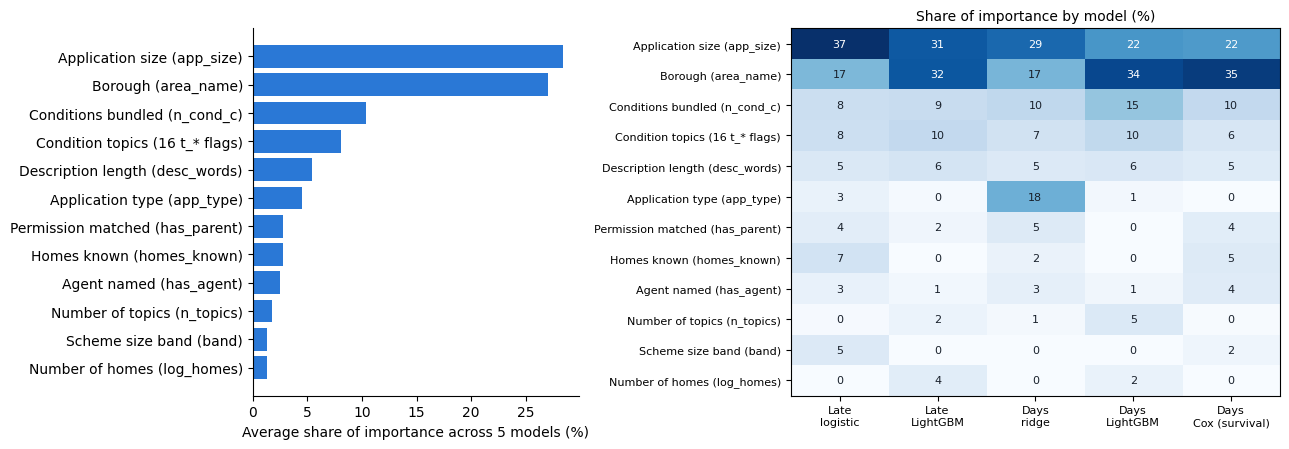

In [11]:
top = summary.head(12)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})

axes[0].barh(top.index[::-1], top["average share %"][::-1], color="#2a78d6")
axes[0].set_xlabel("Average share of importance across 5 models (%)")
axes[0].spines[["top", "right"]].set_visible(False)

heat = top[list(models)]
im = axes[1].imshow(heat.values, cmap="Blues", aspect="auto")
axes[1].set_xticks(range(len(models))); axes[1].set_xticklabels([m.replace(" · ", "\n") for m in models], fontsize=8)
axes[1].set_yticks(range(len(heat))); axes[1].set_yticklabels(heat.index, fontsize=8)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        axes[1].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 20 else "#18202b")
axes[1].set_title("Share of importance by model (%)", fontsize=10)
plt.tight_layout(); plt.show()

**What the five models agree on:**

1. **Application size** (`app_size`, PlanIt's Small/Medium/Large label) and **borough** (`area_name`) are the top two on average, together accounting for over half of what the models use. They're the top two in four of the five models. In the ridge model, application type edges borough into third. Who decides, and how big the application is, matter far more than anything else recorded.
2. **Conditions bundled** is in the top five in every model, and third on average. That's the clearest thing an applicant controls, and it backs up the bundling finding on the page.
3. **Condition topics** (drainage, logistics and so on) come next, then **description length**, which is probably a stand-in for complexity.
4. Timing (month, day of week), recent borough workload and the scheme's history add very little once borough is known.

The same caution as in `02_late_model.ipynb` applies: check how PlanIt sets `app_size` before treating it as a cause.

## 6 · Adding external data

### The method, in four steps

1. **Pick a source that captures something the model can't see yet.** The models are missing council capacity, consultee load, site constraints and scheme detail. Another borough-level average adds little, because borough is already in the model.
2. **Find the join key.**
   - **Borough + date** for council statistics and price trends. Map PlanIt's `area_name` to official names first. *Kensington* is Kensington and Chelsea, *City* is the City of London, and *Old Oak Park Royal* and *London Legacy* are development corporations that cover parts of several boroughs.
   - **Location** (`lat`/`lng`, filled for 95% of applications) for map layers such as conservation areas or flood zones. Use a point-in-polygon spatial join with `geopandas.sjoin`.
   - **Planning reference** for scheme-level data such as the London Development Database.
3. **Join "as of" the submission date, never after.** For time-varying data, use only values published **before** the application was submitted. `pd.merge_asof(..., direction="backward")` does exactly this. Lag by one period, because statistics are published after the period they cover.
4. **Test the gain honestly.** Refit with and without the new features on the **same time split**, and compare the scores. Then check that the new features show up in the importance chart.

### Worked example: local house prices

`external_house_prices.py` turns `hpm_la_2024.zip` (house price per m², already in this folder) into a borough-by-month table: the median price per m² over the last 12 months, and its year-on-year change. The idea is that in a hot market, developers push harder for quick sign-offs, while in a cooling one they're in less of a hurry.

In [12]:
ext = pd.read_csv(paths.OUTPUTS / "ext_house_prices.csv", parse_dates=["month"])
print(f"{ext['area_name'].nunique()} areas, {ext['month'].min():%b %Y} to {ext['month'].max():%b %Y}")

def add_house_prices(X):
    """Attach the house-price figures published for the month BEFORE each application's submission."""
    X = X.copy()
    X["_as_of"] = (X["start_date"].dt.to_period("M") - 1).dt.to_timestamp()
    X = X.sort_values("_as_of")
    out = pd.merge_asof(X, ext[["area_name", "month", "ppm2_12m", "ppm2_yoy"]].sort_values("month"),
                        left_on="_as_of", right_on="month", by="area_name", direction="backward")
    return out.drop(columns=["_as_of", "month_y"]).rename(columns={"month_x": "month"}).set_index(X.index).loc[X.index]

train_x, test_x = add_house_prices(train), add_house_prices(test)
print(f"Applications matched to a price: train {train_x['ppm2_12m'].notna().mean():.0%}, test {test_x['ppm2_12m'].notna().mean():.0%}")
test_x[["name", "area_name", "start_date", "ppm2_12m", "ppm2_yoy"]].head()

35 areas, Jan 2018 to Oct 2024
Applications matched to a price: train 100%, test 100%


,name,area_name,start_date,ppm2_12m,ppm2_yoy
6213,Enfield/24/00010/CND,Enfield,2024-01-02,5714.941022,-1.757945
11519,Lambeth/24/00168/DET,Lambeth,2024-01-17,7702.702703,-0.372229
11518,Lambeth/24/00146/DET,Lambeth,2024-01-16,7702.702703,-0.372229
11517,Lambeth/24/00143/DET,Lambeth,2024-01-15,7702.702703,-0.372229
11516,Lambeth/24/00142/DET,Lambeth,2024-01-15,7702.702703,-0.372229


In [13]:
# Refit the two LightGBM models with and without the new features, on the same split
NEW = ["ppm2_12m", "ppm2_yoy"]

def fit_and_score(feats, label):
    def prep(X):
        X = X[feats].copy()
        for c in CAT:
            X[c] = pd.Categorical(X[c], categories=cat_levels[c])
        return X
    late = lgb.LGBMClassifier(**GBM).fit(prep(train_x), train_x["late"])
    tr_dec = train_x[train_x["decided"] == 1]
    days = lgb.LGBMRegressor(**GBM).fit(prep(tr_dec), np.log1p(tr_dec["days"]))
    return {"features": label,
            "Late AUC": roc_auc_score(test_x["late"], late.predict_proba(prep(test_x))[:, 1]),
            "Days C-index": concordance(test_x["days"], test_x["decided"], days.predict(prep(test_x))),
            "_late": late}

base = fit_and_score(FEATS, "Original features")
plus = fit_and_score(FEATS + NEW, "+ house prices")
hp_compare = pd.DataFrame([base, plus]).drop(columns="_late").set_index("features")
display(hp_compare.round(3))

gain = pd.Series(plus["_late"].booster_.feature_importance("gain"), index=FEATS + NEW)
print("Share of LightGBM gain going to the new features:", (gain[NEW].sum() / gain.sum()).round(3))

,Late AUC,Days C-index
features,,
Original features,0.624,0.558
+ house prices,0.614,0.547


Share of LightGBM gain going to the new features: 0.16


**Reading this:** adding house prices makes both models slightly **worse** on the test years, even though LightGBM gives the new features a large share of its attention. That's a classic warning sign. Within each borough, the price changes month by month, so it acts as a disguised **date stamp**. The model uses it to learn "2021–23 was slow" patterns that don't carry over to 2024–25. The price data also stops in October 2024, so most of the test period uses stale values.

This is exactly why step 4 matters: **a feature can look important and still hurt.** An external source has to add genuinely new information about the application, not a proxy for borough or time.

### Worked example 2: site constraints from planning.data.gov.uk, joined on location

`external_constraints.py` takes five national layers downloaded from planning.data.gov.uk (Data Asset Register row 24), each saved in its own folder under `data/external/planning_data/`, and checks each application's location against them:

| Feature | Meaning |
|---|---|
| `in_conservation_area` | Site is inside a conservation area |
| `listed_within_100m` | Listed buildings within 100 m |
| `brownfield_within_50m` | A brownfield register site within 50 m |
| `in_article4_area` | Site is inside an Article 4 direction area |
| `in_tpo_zone` | Site is inside a tree preservation zone |

Only designations **in force on the submission date** count. Flood risk zones were skipped because that file is 2.5 GB.

**First, check coverage by borough.** The register warns that "absence of a record does not equal absence of the constraint". If a layer is only published by some boroughs, it just becomes a second borough label.

In [14]:
cons = pd.read_csv(paths.OUTPUTS / "ext_constraints.csv")
cons["log_listed"] = np.log1p(cons["listed_within_100m"])
dc = d.merge(cons, on="name", how="left")
print(f"Applications with a location: {dc['in_conservation_area'].notna().mean():.0%}")

cov = (dc.groupby("area_name")[["in_conservation_area", "in_article4_area", "in_tpo_zone", "brownfield_within_50m"]].mean() * 100)
cov["listed nearby"] = dc.assign(l=dc["listed_within_100m"] > 0).groupby("area_name")["l"].mean() * 100
cov["applications"] = dc.groupby("area_name").size()
cov[cov["applications"] >= 200].sort_values("applications", ascending=False).round(0)

Applications with a location: 95%


,in_conservation_area,in_article4_area,in_tpo_zone,brownfield_within_50m,listed nearby,applications
area_name,,,,,,
Croydon,4.0,0.0,0.0,29.0,8.0,2060
Ealing,12.0,0.0,0.0,21.0,13.0,1776
Southwark,11.0,63.0,5.0,60.0,35.0,1547
Lambeth,31.0,12.0,5.0,34.0,38.0,1526
Hounslow,23.0,45.0,0.0,17.0,23.0,1392
Wandsworth,10.0,0.0,0.0,37.0,27.0,1331
Merton,18.0,0.0,0.0,29.0,16.0,904
Enfield,5.0,100.0,0.0,3.0,13.0,839
Kingston,16.0,8.0,6.0,8.0,16.0,791


- **Article 4** is either 0% or 100% within each borough. Some boroughs have borough-wide directions and others haven't published theirs, so it's effectively a borough label.
- **Tree preservation zones** are only published by a handful of boroughs.
- **Conservation areas, listed buildings and brownfield sites** vary in believable ways: high in Kensington and Camden, low in Croydon and Bexley.

So the three reliable layers are tested on their own, and all five are tested for comparison. Each model is fitted with 5 different random seeds, so we can tell a real gain from noise.

In [15]:
ctrain, ctest = time_split(dc)
RELIABLE = ["in_conservation_area", "log_listed", "brownfield_within_50m"]
ALL5 = RELIABLE + ["in_article4_area", "in_tpo_zone"]

def prep_cols(X, feats):
    X = X[feats].copy()
    for c in CAT:
        X[c] = pd.Categorical(X[c], categories=cat_levels[c])
    return X

rows = []
for label, feats in [("Original features", FEATS), ("+ 3 reliable layers", FEATS + RELIABLE), ("+ all 5 layers", FEATS + ALL5)]:
    aucs, cs = [], []
    for seed in range(5):
        params = dict(GBM, random_state=seed)
        late_m = lgb.LGBMClassifier(**params).fit(prep_cols(ctrain, feats), ctrain["late"])
        aucs.append(roc_auc_score(ctest["late"], late_m.predict_proba(prep_cols(ctest, feats))[:, 1]))
        tr_dec = ctrain[ctrain["decided"] == 1]
        days_m = lgb.LGBMRegressor(**params).fit(prep_cols(tr_dec, feats), np.log1p(tr_dec["days"]))
        cs.append(concordance(ctest["days"], ctest["decided"], days_m.predict(prep_cols(ctest, feats))))
    rows.append({"features": label, "Late AUC": np.mean(aucs), "± (5 seeds)": np.std(aucs),
                 "Days C-index": np.mean(cs), "± ": np.std(cs)})
cons_compare = pd.DataFrame(rows).set_index("features")
cons_compare.round(3)

,Late AUC,± (5 seeds),Days C-index,±
features,,,,
Original features,0.627,0.002,0.559,0.001
+ 3 reliable layers,0.630,0.003,0.555,0.002
+ all 5 layers,0.630,0.001,0.557,0.002


**Comparing like with like:** does a constraint change the late rate **within the same borough**? Comparing raw averages would mix up "conservation area" with "Kensington".

In [16]:
dc["listed_nearby"] = (dc["listed_within_100m"] > 0).astype(float).where(dc["listed_within_100m"].notna())
rows = []
for col, label in [("in_conservation_area", "In a conservation area"), ("listed_nearby", "Listed building within 100 m"),
                   ("brownfield_within_50m", "Brownfield site within 50 m")]:
    g = dc.dropna(subset=[col]).groupby(["area_name", col])["late"].agg(["mean", "size"]).unstack(col)
    g = g[(g["size"][0] >= 30) & (g["size"][1] >= 30)]   # boroughs with enough of both
    w = g["size"].sum(axis=1)
    rows.append({"constraint": label,
                 "late, with (%)": 100 * dc.loc[dc[col] == 1, "late"].mean(),
                 "late, without (%)": 100 * dc.loc[dc[col] == 0, "late"].mean(),
                 "difference within borough (points)": 100 * ((g["mean"][1] - g["mean"][0]) * w).sum() / w.sum(),
                 "boroughs compared": len(g)})
cons_within = pd.DataFrame(rows).set_index("constraint")
display(cons_within.round(1))

print("What changes inside a conservation area: share of applications mentioning each topic")
dc.groupby("in_conservation_area")[["t_materials_design_detail", "t_landscaping_trees", "t_drainage_flood"]].mean().mul(100).round(0)

,"late, with (%)","late, without (%)",difference within borough (points),boroughs compared
constraint,,,,
In a conservation area,55.5,56.4,-0.4,15
Listed building within 100 m,58.6,55.6,1.7,16
Brownfield site within 50 m,58.9,55.3,2.4,15


What changes inside a conservation area: share of applications mentioning each topic


,t_materials_design_detail,t_landscaping_trees,t_drainage_flood
in_conservation_area,,,
0.0,18.0,63.0,10.0
1.0,34.0,49.0,8.0


**Reading this:**
- The constraint layers add **almost nothing** to either model. The late-model gain is about the size of the seed-to-seed noise, and the days model doesn't improve.
- **Within the same borough, conservation areas make no difference to lateness**, even though they nearly **double** how often materials and design details are asked for. Listed buildings and brownfield sites nearby add only about 2 points each.
- The conclusion: **site constraints shape *which* conditions are imposed, not *how fast* councils decide them.** That supports the page's message that the delay comes from council process, not the sites themselves.

### Sources worth adding, from the team's Data Asset Register

Ranked by how much new information they would bring to *this* model:

| # | Source (register row) | Join on | What it adds | Effort | Expected gain |
|---|---|---|---|---|---|
| 1 | **Digital Planning Register / borough portals (BOPS)** (25) | Planning reference | Consultee responses (drainage authority, highways), extension-of-time agreements, validation date, officer notes | High: scraping per borough; Lambeth, Southwark and Camden are on BOPS | **High.** These are the real drivers the model can't see now |
| 2 | **PlanIt API** (26) | Planning reference | Fills the boroughs that are thin here (Barnet, Tower Hamlets, Westminster, Newham), and lets you check how `app_size` is set | Medium: rate-limited to about 1 request a minute | **Medium–high.** More data, and settles the `app_size` question |
| ✓ | **Planning Data: constraint layers** (24) | `lat`/`lng`, spatial join | Conservation area, listed buildings, brownfield (Article 4 and tree zones too patchy) | Done above | **Very low.** Changes what is asked, not speed. Flood zones still untested (2.5 GB) |
| 4 | **MHCLG live planning tables** (28) | Borough + previous quarter | Each council's overall decision volumes and on-time rates, a capacity and workload signal that changes over time | Low: quarterly CSV | **Low–medium.** Partly repeats borough, but shows change over time |
| 5 | **London Plan Opportunity Areas** (27) | `lat`/`lng` | Whether the site is in a GLA growth area (bigger, more complex schemes) | Low | Low–medium |
| 6 | **LDD / Planning London Datahub** (14, 15) | Planning reference | Scheme detail (homes, tenure, start dates) to fill the half of applications with unknown size and to improve permission matching | Medium–high: the LDD is a 2020 archive and the Datahub has no bulk download | Medium, but awkward to get |
| 7 | **Indices of Deprivation 2025** (9) | `lat`/`lng` to LSOA | Local context | Medium: needs LSOA boundaries | Low |
| – | House prices per m² (36) | Borough + month | Market heat | Done above | None: slightly worse |

**Recommended next step:** both worked examples point the same way. Data about the **area** adds little, because borough already captures it. What's missing is data about **each case**: consultee responses, extension-of-time agreements and validation dates. So the next steps are:
1. **PlanIt API** (#2): quick, and settles the `app_size` question.
2. **Borough portals / BOPS** (#1): start with Lambeth, Southwark and Camden, which are already on the Digital Planning Register.

## 7 · Reading the description with JEV

The description features used so far (topics, number of conditions, pre-start flag) come from **keyword matching**. That reads the whole description, including the copied text of the original permission ("…41 flats with cycle storage, refuse storage and landscaping"), so it often tags the scheme rather than the condition being signed off.

**Jev** (`~typesafe/jev-latest`, through OpenRouter's decisions API) was asked typed questions about each description's request part: a probability for each of the 16 topics, the number of conditions, whether the topic is stated, and whether the details are needed before work starts. The process is explained in full in section 8 of `02_late_model.ipynb`. The labels are cached in `outputs/jev_topics.jsonl`, so this notebook makes no API calls.

Below, all five models are refitted with JEV's description features in place of the keyword ones. Everything else stays the same.

In [17]:
from conditions_queue.features import add_jev_features, NUM_JEV, JEV_TOPIC_COLS
dj, jev_coverage = add_jev_features(d)
trj, tej = time_split(dj)
print(f"Applications with a JEV label: {jev_coverage:.1%}")

FEATS_J = CAT + NUM_JEV
med_j = trj[NUM_JEV].median()
prep_linear_j = lambda X: X[FEATS_J].fillna(med_j)
def prep_tree_j(X):
    X = X[FEATS_J].copy()
    for c in CAT:
        X[c] = pd.Categorical(X[c], categories=cat_levels[c])
    return X
encoder_j = lambda: ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT), ("num", StandardScaler(), NUM_JEV)])
trj_dec = trj[trj["decided"] == 1]

models_j = {}
lj = make_pipeline(encoder_j(), LogisticRegression(max_iter=2000, C=0.5)).fit(prep_linear_j(trj), trj["late"])
models_j["Late · logistic"] = ("late", lambda X: lj.predict_proba(prep_linear_j(X))[:, 1])
gj = lgb.LGBMClassifier(**GBM).fit(prep_tree_j(trj), trj["late"])
models_j["Late · LightGBM"] = ("late", lambda X: gj.predict_proba(prep_tree_j(X))[:, 1])
rj = make_pipeline(encoder_j(), Ridge(alpha=1.0)).fit(prep_linear_j(trj_dec), np.log1p(trj_dec["days"]))
models_j["Days · ridge"] = ("days", lambda X: np.expm1(rj.predict(prep_linear_j(X))))
gdj = lgb.LGBMRegressor(**GBM).fit(prep_tree_j(trj_dec), np.log1p(trj_dec["days"]))
models_j["Days · LightGBM"] = ("days", lambda X: np.expm1(gdj.predict(prep_tree_j(X))))

cox_enc_j = encoder_j().fit(prep_linear_j(trj))
names_j = cox_enc_j.get_feature_names_out()
keep_j = np.ones(len(names_j), bool)
for c in CAT:
    counts = trj[c].value_counts()
    for i, n in enumerate(names_j):
        if n.startswith(f"cat__{c}_"):
            level = n[len(f"cat__{c}_"):]
            if level == counts.index[0] or counts.get(level, 0) < 30:
                keep_j[i] = False
# drop JEV topic flags that are (almost) never used, which would make the Cox model unsolvable
for i, n in enumerate(names_j):
    raw = n.replace("num__", "")
    if raw in JEV_TOPIC_COLS and trj[raw].sum() < 30:
        keep_j[i] = False
def cox_matrix_j(X):
    Z = cox_enc_j.transform(prep_linear_j(X))
    return (Z.toarray() if hasattr(Z, "toarray") else Z)[:, keep_j]
cox_j = PHReg(trj["days"].clip(lower=0.5).values, cox_matrix_j(trj), status=trj["decided"].values, ties="efron").fit()
models_j["Days · Cox (survival)"] = ("days", lambda X: -(cox_matrix_j(X) @ cox_j.params))

jev_rows = []
for name in models:
    kind, f_kw = models[name]
    _, f_j = models_j[name]
    pk, pj = f_kw(test), f_j(tej)
    jev_rows.append({"model": name,
                     "C-index (keyword)": concordance(test["days"], test["decided"], pk),
                     "C-index (JEV)": concordance(tej["days"], tej["decided"], pj),
                     "AUC (keyword)": roc_auc_score(test["late"], pk) if kind == "late" else np.nan,
                     "AUC (JEV)": roc_auc_score(tej["late"], pj) if kind == "late" else np.nan})
jev_scores = pd.DataFrame(jev_rows).set_index("model")
jev_scores["C-index change"] = jev_scores["C-index (JEV)"] - jev_scores["C-index (keyword)"]
jev_scores.round(3)

Applications with a JEV label: 100.0%


/Applications/anaconda3/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,C-index (keyword),C-index (JEV),AUC (keyword),AUC (JEV),C-index change
model,,,,,
Late · logistic,0.575,0.581,0.615,0.623,0.006
Late · LightGBM,0.583,0.588,0.628,0.634,0.005
Days · ridge,0.561,0.568,NaN,NaN,0.007
Days · LightGBM,0.558,0.567,NaN,NaN,0.009
Days · Cox (survival),0.570,0.574,NaN,NaN,0.004


### Does the description help at all?

The fairest test: fit every model three ways on the same applications and split.
1. **No description features**: borough, size, timing, workload and scheme history only.
2. **Keyword description features**: plus the keyword tagger's topics, condition count and pre-start flag.
3. **Jev description features**: plus Jev's topics, condition count, topic-stated and pre-start flags instead.

LightGBM is averaged over 5 seeds, so small differences can be told apart from noise.

In [18]:
from conditions_queue.features import KEYWORD_TEXT_COLS
NO_TEXT = [c for c in NUM if c not in KEYWORD_TEXT_COLS]

def evaluate(num, seeds=5):
    feats = CAT + num
    med = trj[num].median()
    lin = lambda X: X[feats].fillna(med)
    def tree(X):
        X = X[feats].copy()
        for c in CAT:
            X[c] = pd.Categorical(X[c], categories=cat_levels[c])
        return X
    enc = lambda: ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT), ("num", StandardScaler(), num)])
    tr_dec, te_dec = trj[trj["decided"] == 1], tej[tej["decided"] == 1]
    out = {}
    lg = make_pipeline(enc(), LogisticRegression(max_iter=2000, C=0.5)).fit(lin(trj), trj["late"])
    out["late_logistic_auc"] = roc_auc_score(tej["late"], lg.predict_proba(lin(tej))[:, 1])
    aucs, cs, maes = [], [], []
    for s in range(seeds):
        p = dict(GBM, random_state=s)
        m = lgb.LGBMClassifier(**p).fit(tree(trj), trj["late"])
        aucs.append(roc_auc_score(tej["late"], m.predict_proba(tree(tej))[:, 1]))
        r = lgb.LGBMRegressor(**p).fit(tree(tr_dec), np.log1p(tr_dec["days"]))
        cs.append(concordance(tej["days"], tej["decided"], r.predict(tree(tej))))
        maes.append(mean_absolute_error(te_dec["days"], np.expm1(r.predict(tree(te_dec)))))
    out["late_lightgbm_auc"], out["late_lightgbm_sd"] = np.mean(aucs), np.std(aucs)
    out["days_lightgbm_c"], out["days_lightgbm_sd"], out["days_lightgbm_mae"] = np.mean(cs), np.std(cs), np.mean(maes)
    rg = make_pipeline(enc(), Ridge(alpha=1.0)).fit(lin(tr_dec), np.log1p(tr_dec["days"]))
    out["days_ridge_c"] = concordance(tej["days"], tej["decided"], rg.predict(lin(tej)))
    out["days_ridge_mae"] = mean_absolute_error(te_dec["days"], np.expm1(rg.predict(lin(te_dec))))
    ce = enc().fit(lin(trj)); nm = ce.get_feature_names_out(); keep = np.ones(len(nm), bool)
    for c in CAT:
        counts = trj[c].value_counts()
        for i, n in enumerate(nm):
            if n.startswith(f"cat__{c}_") and (n[len(f"cat__{c}_"):] == counts.index[0] or counts.get(n[len(f"cat__{c}_"):], 0) < 30):
                keep[i] = False
    for i, n in enumerate(nm):
        raw = n.replace("num__", "")
        if raw in num and (trj[raw].nunique() <= 1 or (set(trj[raw].dropna().unique()) <= {0, 1} and trj[raw].sum() < 30)):
            keep[i] = False
    Zf = lambda X: (lambda Z: (Z.toarray() if hasattr(Z, "toarray") else Z)[:, keep])(ce.transform(lin(X)))
    cx = PHReg(trj["days"].clip(lower=0.5).values, Zf(trj), status=trj["decided"].values, ties="efron").fit()
    out["days_cox_c"] = concordance(tej["days"], tej["decided"], -(Zf(tej) @ cx.params))
    return out

desc_rows = []
for label, num in [("No description features", NO_TEXT), ("Keyword description features", NUM), ("Jev description features", NUM_JEV)]:
    desc_rows.append({"features": label, **evaluate(num)})
description_value = pd.DataFrame(desc_rows).set_index("features")
display(description_value.round(3))

gain = description_value.drop(columns=[c for c in description_value if c.endswith("_sd")]) - description_value.loc["No description features"]
print("Change against no description features (AUC and C-index points; MAE in days, negative is better):")
gain.round(3)

/Applications/anaconda3/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/Applications/anaconda3/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,late_logistic_auc,late_lightgbm_auc,late_lightgbm_sd,days_lightgbm_c,days_lightgbm_sd,days_lightgbm_mae,days_ridge_c,days_ridge_mae,days_cox_c
features,,,,,,,,,
No description features,0.593,0.596,0.001,0.539,0.001,40.981,0.544,39.280,0.561
Keyword description features,0.615,0.627,0.002,0.559,0.001,40.997,0.561,39.624,0.570
Jev description features,0.623,0.636,0.001,0.565,0.001,40.598,0.568,39.348,0.574


Change against no description features (AUC and C-index points; MAE in days, negative is better):


,days_cox_c,days_lightgbm_c,days_lightgbm_mae,days_lightgbm_sd,days_ridge_c,days_ridge_mae,late_lightgbm_auc,late_lightgbm_sd,late_logistic_auc
features,,,,,,,,,
No description features,0.000,0.000,0.000,NaN,0.000,0.000,0.000,NaN,0.000
Keyword description features,0.010,0.021,0.017,NaN,0.017,0.344,0.030,NaN,0.022
Jev description features,0.013,0.026,-0.383,NaN,0.024,0.068,0.039,NaN,0.031


**Reading this:**
- **For late or not, the description is the biggest single improvement after borough and size.** LightGBM goes from 0.596 with no description features to 0.627 with keyword features and **0.636 with Jev's**. Logistic regression goes from 0.593 to 0.615 to 0.623. Each step is much larger than the ±0.001–0.002 seed noise.
- **For decision time, the description improves the ordering of applications, not the number of days.** C-index rises in every days model (LightGBM 0.539 → 0.559 → 0.565, Cox 0.561 → 0.570 → 0.574, ridge 0.544 → 0.561 → 0.568). The average error stays at about 39–41 days in all three versions, because most decisions cluster at the 8-week deadline regardless.
- **Jev beats the keyword tagger in every one of the six comparisons.** The gain is small but consistent, which is what you'd expect from cleaner labels for the same information.
- The Cox model sometimes warns that it hasn't fully converged with the larger feature sets. Its C-index moves the same way as the other models, so the conclusion holds.

### The biggest predictors again, with JEV's description features

,average share %,average rank,top 5 in how many models,Late · logistic,Late · LightGBM,Days · ridge,Days · LightGBM,Days · Cox (survival)
Application size (app_size),27.1,1.4,5,35.4,32.0,28.1,21.0,19.0
Borough (area_name),25.4,1.6,5,18.8,28.3,18.3,27.9,33.5
"Condition topics, Jev (16 jev_* flags)",11.4,3.4,5,8.5,12.8,10.1,18.1,7.6
"Conditions bundled, Jev (jev_n_cond_c)",11.3,4.0,5,7.5,8.3,9.3,17.6,13.5
Application type (app_type),4.6,10.8,1,3.0,0.3,17.7,1.8,0.0
Description length (desc_words),4.1,6.6,1,4.1,5.1,3.6,4.3,3.4
Permission matched (has_parent),3.2,7.6,0,4.7,2.1,3.7,0.2,5.1
Scheme's earlier sign-offs (scheme_prior_apps),2.7,10.2,1,3.3,0.5,2.9,0.0,6.9
Homes known (homes_known),2.5,11.8,1,6.7,0.0,2.8,0.0,3.1
Number of homes (log_homes),1.9,13.8,1,0.0,6.4,0.0,2.9,0.0


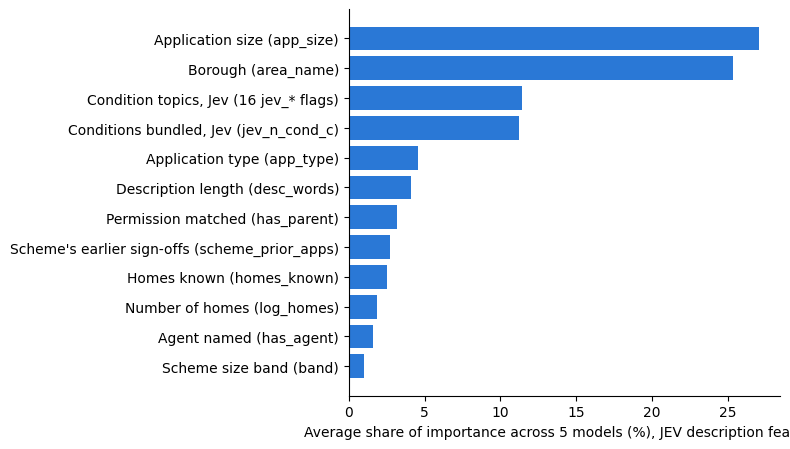

Cox, JEV count: each extra condition bundled multiplies the daily chance of a decision by 0.91 (9% slower per condition)


In [19]:
GROUPS_J = {f: [f] for f in FEATS_J if f not in JEV_TOPIC_COLS}
GROUPS_J["jev_topics"] = JEV_TOPIC_COLS
rng = np.random.default_rng(0)
drops_j = {}
for name, (kind, f) in models_j.items():
    base_score = model_score(kind, tej, f(tej))
    drops_j[name] = {}
    for g, cols in GROUPS_J.items():
        vals = []
        for _ in range(3):
            sh = tej.copy()
            sh[cols] = sh[cols].values[rng.permutation(len(sh))]
            vals.append(base_score - model_score(kind, sh, f(sh)))
        drops_j[name][g] = np.mean(vals)
drops_j = pd.DataFrame(drops_j)
share_j = drops_j.clip(lower=0) / drops_j.clip(lower=0).sum() * 100
summary_j = pd.DataFrame({"average share %": share_j.mean(axis=1),
                          "average rank": drops_j.rank(ascending=False).mean(axis=1),
                          "top 5 in how many models": (drops_j.rank(ascending=False) <= 5).sum(axis=1)}).join(share_j.round(1))
summary_j = summary_j.sort_values("average share %", ascending=False)
summary_j.index = summary_j.index.map(lambda k: LABELS.get(k, k))
display(summary_j.round(1).head(12))

top_j = summary_j.head(12)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top_j.index[::-1], top_j["average share %"][::-1], color="#2a78d6")
ax.set_xlabel("Average share of importance across 5 models (%), JEV description features")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

sd_j = trj["jev_n_cond_c"].std()
per_cond_j = np.exp(cox_j.params[list(names_j[keep_j]).index("num__jev_n_cond_c")] / sd_j)
print(f"Cox, JEV count: each extra condition bundled multiplies the daily chance of a decision by {per_cond_j:.2f} "
      f"({1 - per_cond_j:.0%} slower per condition)")

**Reading this:**
- With Jev's labels, **condition topics** (11% of importance) and **conditions bundled** (11%) are the third and fourth biggest predictors on average, behind application size and borough. Both are in the top five of all five models. With keyword labels they were 8% and 10%.
- **Each extra condition bundled slows the decision by about 9%** in the Cox model using Jev's counts, against 8% with the keyword counts. Cleaner counts make the bundling effect slightly stronger.
- Every model's C-index improves a little with Jev's description features in place of the keyword ones (+0.004 to +0.009).

## 8 · Summary

- **Target:** `days` from submission to decision. Undecided applications count as "at least this many days so far". Ridge and LightGBM model log(1 + days), the Cox survival model uses the censoring directly, and the quantile models give P50 and P90.
- **How well it works:** decision time can't be predicted to the day. Most decisions land around day 56, so each borough's median is already about as accurate as anything (median error 20 days, 62% within 4 weeks). The models **order** applications better (C-index up to 0.57) and pick out the slow tail. The useful output is a range: the P90 "plan for" date held for 93% of applications.
- **The description helps the ordering, not the day count.** Adding description features raises every days model's C-index (LightGBM 0.539 → 0.565 with Jev), but the average error stays at about 40 days.
- **Across all five models, the biggest predictors are the same:** application size and borough, then Jev's condition topics and conditions bundled. Bundling is the strongest factor an applicant controls: each extra condition slows the decision by about 9%.
- **External data** only helps if it adds something new. Borough-level house prices made the models slightly worse, because they act as a disguised date stamp. Site constraints added almost nothing. The promising additions are **case-level** data: consultee responses and extensions of time from borough portals.

## 9 · Save results for the UI

In [20]:
import json
def records(df):
    return json.loads(df.reset_index().to_json(orient="records"))
p_rng = rng_df.groupby(rng_df["n_cond"].clip(upper=7)).agg(applications=("days", "size"), P50=("P50", "median"),
                                                          P90=("P90", "median"), actual_median=("days", "median"))
ui = {
    "notebook": "03_days_model.ipynb",
    "days_summary": {"median_decided": float(d.loc[d["decided"] == 1, "days"].median()),
                     "n_undecided": int((d["decided"] == 0).sum()),
                     "p90_coverage": float((rng_df["days"] <= rng_df["P90"]).mean()),
                     "per_condition_slowdown": float(1 - per_cond), "per_condition_slowdown_jev": float(1 - per_cond_j)},
    "scores": records(scores),
    "ranges_by_conditions": records(p_rng.rename_axis("conditions")),
    "cox_effects": records(show.rename_axis("feature")),
    "importance_keyword": records(summary[["average share %", "average rank", "top 5 in how many models"] + list(models)].rename_axis("feature")),
    "importance_jev": records(summary_j[["average share %", "average rank", "top 5 in how many models"] + list(models_j)].rename_axis("feature")),
    "jev_scores": records(jev_scores),
    "days_accuracy": records(days_accuracy),
    "days_calibration": records(days_calibration.rename_axis("group")),
    "description_value": records(description_value),
    "external": {"house_prices": records(hp_compare), "constraints": records(cons_compare),
                 "constraints_within_borough": records(cons_within)},
}
with open(paths.OUTPUTS / "ui_days_model.json", "w") as f:
    json.dump(ui, f, indent=1)
print("wrote outputs/ui_days_model.json")

wrote outputs/ui_days_model.json
